In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import importlib
from scipy.stats import gaussian_kde, multivariate_normal
import scipy.constants as c
import encs as E
importlib.reload(E)

# from BT_E1_E19 import *

<module 'encs' from '/data/home/goodwill/Goodwill2026_GRL/encs.py'>

In [2]:
import pandas as pd
import numpy as np
import encs as E

dfs = []
enc_range = np.arange(1,20)
for enc in enc_range:
    if enc < 8:
        print(f"Loading {enc}")
        
        df = pd.read_parquet(f"psp_E1_E19_10s_comb/E{enc}_comb_10s.parquet")
        df.index = pd.to_datetime(df.index)
        df = df.rename(columns={
        "Br": "BR",
        "Bt": "BT",
        "Bn": "BN",
        "MA_comb" : "MA",
        'r_AU':'R',
        })
        df = df.select_dtypes(include="number").resample("10s").mean()
        
        # optional: add encounter label
        
    elif enc > 8:
        df = E.load_all_encounters([enc], res = 10)
        df['MA'] = E.M_A(df)
        df['R'] = E.load_R(df.index, 60)
        df['R'] = df['R'] * 0.00465047
        df['R'] = df['R'].interpolate(method="time", limit_area="inside")
        # print(df.keys())
        
    # print(f"Loading {enc}")
        
    df["encounter"] = enc
    dfs.append(df)

# combine everything
df = pd.concat(dfs).sort_index()

# print(df.head())

Loading 1
Loading 2
Loading 3
Loading 4
Loading 5
Loading 6
Loading 7


In [3]:
def PSP_acf(
    df,
    window="3h",
    step="3h",
    dt_seconds=10.0,
    max_lag=1000,
    lag_window=None,
    method="efolding",
):
    """
    Run sliding-window analysis over PSP data and store ALL ACFs + metadata.

    Returns
    -------
    results : dict of lists
        {
            "acf": [...],         # each is array
            "tau": [...],         # lag arrays (same length as acf)
            "tau_c": [...],       # correlation time [seconds]
            "tau_1e": [...],      # preliminary 1/e time
            "ma": [...],          # mean M_A
            "start": [...],
            "end": [...],
            "center": [...],
        }
    """

    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("df must have DatetimeIndex")

    df = df.sort_index()

    window = pd.Timedelta(window)
    step = pd.Timedelta(step)

    starts = pd.date_range(
        start=df.index.min(),
        end=df.index.max() - window,
        freq=step,
    )


    acf_list = []
    tau_list = []
    tau_c_list = []
    tau_1e_list = []
    ma_list = []
    start_list = []
    end_list = []
    center_list = []
    R_list = []


    for start in starts:
        end = start + window
        center = start + window / 2

        dfw = df.loc[start:end]

        if len(dfw) == 0:
            continue

        # valid rows
        mask = np.isfinite(dfw["BR"]) & np.isfinite(dfw["BT"]) & np.isfinite(dfw["BN"])

        n_total = len(dfw)
        n_valid = mask.sum()

        br = dfw.loc[mask, "BR"].to_numpy()
        bt = dfw.loc[mask, "BT"].to_numpy()
        bn = dfw.loc[mask, "BN"].to_numpy()


        acf = mag_acf(
            br, bt, bn, max_lag=max_lag, lag_window=lag_window
        )

        if ((len(acf) < max_lag)) :
            # or (np.any(np.abs(acf[max_lag/:]) > 1/np.e)))
            continue

        tau = np.arange(len(acf)) * dt_seconds


        if method == "efolding":
            tau_c = efolding_time(acf, dt_seconds)
        elif method == "integral":
            tau_c = integral_time(acf, dt_seconds)
        else:
            raise ValueError("method must be 'efolding' or 'integral'")

        tau_1e = efolding_time(acf, dt_seconds)

        ma_mean = np.nan
        if "MA" in dfw.columns:
            ma_mean = np.nanmean(dfw.loc[mask, "MA"])


        acf_list.append(acf)
        tau_list.append(tau)
        tau_c_list.append(tau_c)
        tau_1e_list.append(tau_1e)
        ma_list.append(ma_mean)
        start_list.append(start)
        end_list.append(end)
        center_list.append(center)
        R_list.append(np.mean(dfw['R']))


    return {
        "acf": acf_list,
        "R" : R_list,
        "tau": tau_list,
        "tau_c": tau_c_list,
        "tau_1e": tau_1e_list,
        "ma": ma_list,
        "start": start_list,
        "end": end_list,
        "center": center_list,
    }

In [4]:
def BT_acf(x, max_lag=None, lag_window = None):
    """
    Estimate the autocovariance using the Blackman-Tukey approach.

    Parameters
    ----------
    x : array-like
        1D signal.
    max_lag : int or None
        Maximum lag in samples. If None, use len(x)//4.
    lag_window : str or None
        Lag window applied to the autocovariance estimate.
        Options:
            None       -> no lag window
            "blackman" -> Blackman lag window
            "hann"     -> Hann lag window
            "bartlett" -> Bartlett (triangular) lag window

    Returns
    -------
    acov : ndarray
        Autocovariance estimate from lag 0 to max_lag.
    """
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)
    if n < 10:
        return np.array([])

    if max_lag is None:
        max_lag = n // 4

    max_lag = min(max_lag, n - 1)

    x = x - np.nanmean(x)
    acov = np.empty(max_lag + 1)

    for lag in range(max_lag + 1):
        left = x[: n - lag]
        right = x[lag:]
        acov[lag] = np.nanmean(left * right)
        
        
    if lag_window is not None:
        m = max_lag + 1
        if lag_window == "blackman":
            w = np.blackman(2 * m - 1)[m - 1 :]
        elif lag_window == "hann":
            w = np.hanning(2 * m - 1)[m - 1 :]
        elif lag_window == "bartlett":
            w = np.bartlett(2 * m - 1)[m - 1 :]
        elif lag_window == 'tukey':
            w = tukey(m, alpha = 0.1)
        else:
            raise ValueError("lag_window must be None, 'blackman', 'hann', or 'bartlett'")
        acov = acov * w
        # print('XXXXXXXXXXXXXX')
        # print(w)
    # cos_fac = 1/2*(1+math.cos((math.pi/(0.1*max_lag))*(lagtime_copy[neg_ind]-0.9*tau_max)))
    if len(acov) == 0 or not np.isfinite(acov[0]) or acov[0] <= 0:
        return np.array([])
    acov = acov / acov[0]
    # if len(acov) == 0 or not np.all(np.isfinite(acov)) or  not np.isfinite(acov[0]) or acov[0] <= 0 or np.max(acov[1:]) > 1.2 or np.min(acov[1:]) < -0.5:
    #     return np.array([])

    return acov




def mag_acf(
    br, bt, bn, max_lag=None, lag_window=None
):
    """
    Trace autocorrelation of vector magnetic fluctuations using
    Blackman-Tukey component autocorrelations weighted by variance.

    Parameters
    ----------
    br, bt, bn : array-like
        Magnetic field components.
    max_lag : int or None
        Maximum lag in samples.
    lag_window : str or None
        Lag window for Blackman-Tukey estimation.

    Returns
    -------
    R : ndarray
        Normalized trace autocorrelation, with R[0] = 1.
    """
    br = np.asarray(br, dtype=float)
    bt = np.asarray(bt, dtype=float)
    bn = np.asarray(bn, dtype=float)

    mask = np.isfinite(br) & np.isfinite(bt) & np.isfinite(bn)
    br, bt, bn = br[mask], bt[mask], bn[mask]

    if len(br) < 10:
        return np.array([])

    dbr = br - np.mean(br)
    dbt = bt - np.mean(bt)
    dbn = bn - np.mean(bn)

    Rr = BT_acf(dbr, max_lag=max_lag, lag_window= lag_window)
    Rt = BT_acf(dbt, max_lag=max_lag, lag_window= lag_window)
    Rn = BT_acf(dbn, max_lag=max_lag, lag_window= lag_window)

    nmin = min(len(Rr), len(Rt), len(Rn))
    if nmin == 0:
        return np.array([])
    R = Rr + Rt + Rn


    return R/R[0]


def efolding_time(acf, dt_seconds):
    """
    Correlation time from first 1/e crossing of the ACF.
    """
    acf = np.asarray(acf, dtype=float)

    if len(acf) < 2:
        return np.nan

    target = 1.0 / np.e
    idx = np.where(acf <= target)[0]

    if len(idx) == 0:
        return np.nan

    i = idx[0]
    if i == 0:
        return 0.0

    x0, x1 = (i - 1) * dt_seconds, i * dt_seconds
    y0, y1 = acf[i - 1], acf[i]

    if y1 == y0:
        return x1

    return x0 + (target - y0) * (x1 - x0) / (y1 - y0)


def integral_time(acf, dt_seconds):
    """
    Integral correlation time, integrated to first zero crossing.
    """
    acf = np.asarray(acf, dtype=float)

    if len(acf) < 2:
        return np.nan

    idx = np.where(acf <= 0)[0]
    end = idx[0] if len(idx) > 0 else len(acf) - 1

    tau = np.arange(end + 1) * dt_seconds
    return np.trapz(acf[: end + 1], tau)


def PSP_acf(
    df,
    window="3h",
    step="3h",
    dt_seconds=10.0,
    max_lag=1000,
    lag_window=None,
    method="efolding",
):
    """
    Run sliding-window analysis over PSP data and store ALL ACFs + metadata.

    Returns
    -------
    results : dict of lists
        {
            "acf": [...],         # each is array
            "tau": [...],         # lag arrays (same length as acf)
            "tau_c": [...],       # correlation time [seconds]
            "tau_1e": [...],      # preliminary 1/e time
            "ma": [...],          # mean M_A
            "start": [...],
            "end": [...],
            "center": [...],
        }
    """

    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("df must have DatetimeIndex")

    df = df.sort_index()

    window = pd.Timedelta(window)
    step = pd.Timedelta(step)

    starts = pd.date_range(
        start=df.index.min(),
        end=df.index.max() - window,
        freq=step,
    )


    acf_list = []
    tau_list = []
    tau_c_list = []
    tau_1e_list = []
    ma_list = []
    start_list = []
    end_list = []
    center_list = []
    R_list = []
    enc_list = []


    for start in starts:
        end = start + window
        center = start + window / 2

        dfw = df.loc[start:end]

        if len(dfw) == 0:
            continue

        # valid rows
        mask = np.isfinite(dfw["BR"]) & np.isfinite(dfw["BT"]) & np.isfinite(dfw["BN"])

        n_total = len(dfw)
        n_valid = mask.sum()

        br = dfw.loc[mask, "BR"].to_numpy()
        bt = dfw.loc[mask, "BT"].to_numpy()
        bn = dfw.loc[mask, "BN"].to_numpy()


        acf = mag_acf(
            br, bt, bn, max_lag=max_lag, lag_window=lag_window
        )

        if ((len(acf) < max_lag)) or (np.any(np.abs(acf[max_lag//2:]) > 1/np.e)):
            continue

        tau = np.arange(len(acf)) * dt_seconds


        if method == "efolding":
            tau_c = efolding_time(acf, dt_seconds)
        elif method == "integral":
            tau_c = integral_time(acf, dt_seconds)
        else:
            raise ValueError("method must be 'efolding' or 'integral'")

        tau_1e = efolding_time(acf, dt_seconds)

        ma_mean = np.nan
        if "MA" in dfw.columns:
            ma_mean = np.nanmean(dfw.loc[mask, "MA"])


        acf_list.append(acf)
        tau_list.append(tau)
        tau_c_list.append(tau_c)
        tau_1e_list.append(tau_1e)
        ma_list.append(ma_mean)
        start_list.append(start)
        end_list.append(end)
        center_list.append(center)
        R_list.append(np.mean(dfw['R']))
        enc_list.append(dfw['encounter'].iloc[0])


    return {
        "acf": acf_list,
        "R" : R_list,
        "tau": tau_list,
        "tau_c": tau_c_list,
        "tau_1e": tau_1e_list,
        "ma": ma_list,
        "start": start_list,
        "end": end_list,
        "center": center_list,
        'enc': enc_list
    }


In [5]:
win = '4h'
# from BT_E1_E19 import PSP_acf
results = PSP_acf(
    df,
    window=win,
    step='4h',
    dt_seconds=10.0,
    max_lag=540,
    lag_window='blackman',
    method="efolding",
)
print(results)


acf_list = results["acf"]
tau_list = results["tau"]
tau_c_list = results["tau_c"]
ma_list = results["ma"]
R_list = np.array(results['R'])
enc_list = np.array(results['enc'])



tau_c = np.array(results["tau_c"])
ma = np.array(results["ma"])
mask = np.isfinite(tau_c) & np.isfinite(ma) & (tau_c > 0)
tau_c = tau_c[mask]
ma = ma[mask]
R_list = R_list[mask]
enc_list = enc_list[mask]

/tmp/ipykernel_3413705/3408102722.py:259: RuntimeWarning: Mean of empty slice
  ma_mean = np.nanmean(dfw.loc[mask, "MA"])


{'acf': [array([ 1.00000000e+00,  9.74465545e-01,  9.45450075e-01,  9.19132962e-01,
        8.93041262e-01,  8.67332574e-01,  8.42452393e-01,  8.19181511e-01,
        7.99254588e-01,  7.81283070e-01,  7.66408190e-01,  7.53168535e-01,
        7.41752548e-01,  7.31776732e-01,  7.21701622e-01,  7.13127094e-01,
        7.04927203e-01,  6.96166468e-01,  6.88573727e-01,  6.81732982e-01,
        6.73774291e-01,  6.66059633e-01,  6.58128360e-01,  6.52375727e-01,
        6.47457176e-01,  6.41741053e-01,  6.35366438e-01,  6.28741695e-01,
        6.21850860e-01,  6.15690034e-01,  6.09640937e-01,  6.03349240e-01,
        5.96818055e-01,  5.89207302e-01,  5.80663739e-01,  5.72761605e-01,
        5.65033890e-01,  5.57204979e-01,  5.51396672e-01,  5.46682334e-01,
        5.40591229e-01,  5.33421557e-01,  5.28577905e-01,  5.22738766e-01,
        5.16848915e-01,  5.10133119e-01,  5.03776758e-01,  4.98829106e-01,
        4.93740626e-01,  4.88482725e-01,  4.82990299e-01,  4.78349601e-01,
        4.733031

In [6]:
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 30,
    'axes.labelsize': 40,
    'xtick.labelsize': 40,
    'xtick.major.pad': 5,
    'xtick.major.size':    3.5,
    'xtick.minor.size':    0,
    'ytick.labelsize': 30,
    'legend.fontsize': 30,
    'legend.title_fontsize' : 30,
    'figure.titlesize': 18,
    'figure.labelsize': 40,
    'xtick.major.size':    10,
    'xtick.minor.size':    8,
    'ytick.major.size':    10,
    'ytick.minor.size':    8,
    'xtick.major.width':   3,
    'xtick.minor.width':   2,
    'ytick.major.width':   3,
    'ytick.minor.width':   2,
    'pdf.compression': 9
})

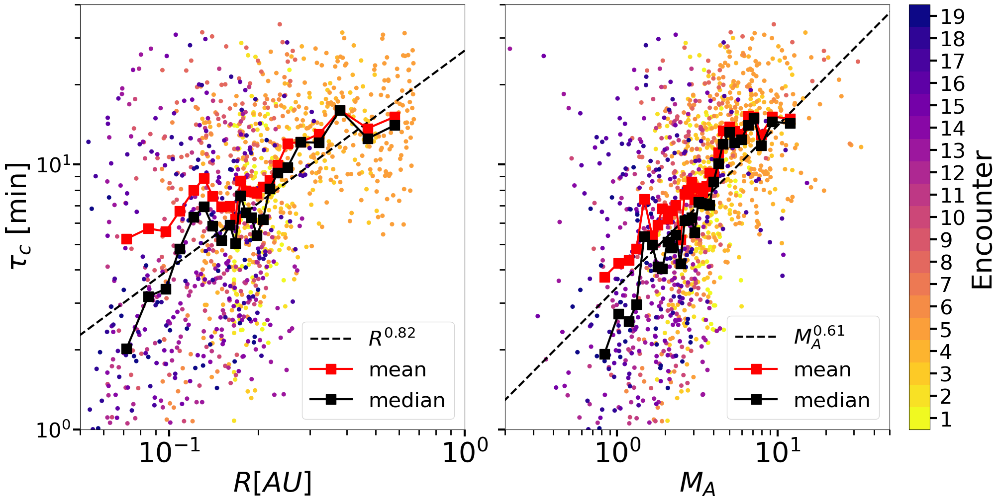

In [7]:
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FormatStrFormatter
'''
tau_c vs MA
'''

bins = E.bin_average(ma, tau_c, N=40)



fig, ax = plt.subplots(1,2, figsize=(20, 10), sharey = True, layout="constrained")

cmin = 0
cmax = 0.3

# Number of encounters
n_enc = 19

n_encs = (np.linspace(0, 1, 19))

# cmap = ListedColormap(colors)

cmap = plt.get_cmap('plasma_r')  # or 'plasma', 'magma', 'cividis', 'turbo'

bounds = np.arange(0.5, 20.5, 1)
norm = BoundaryNorm(bounds, cmap.N)

n = 1
ma = np.asarray(ma, dtype=float)
tau = np.asarray(tau_c, dtype=float)
enc = np.asarray(enc_list, dtype = float)


scr = ax[n].scatter(ma, tau / 60.0,
              alpha=1, s=30, c = enc, cmap='plasma_r', norm=norm)




ax[n].errorbar(
    bins.x_center[1:-1], bins.y_mean[1:-1] / 60, fmt="red", marker="s", ms=15, lw=3, label = 'mean'
)

ax[n].errorbar(
    bins.x_center[1:-1], bins.y_median[1:-1] / 60, fmt="black", marker="s", ms=15, lw=3, label = 'median'
)

ma = np.asarray(ma, dtype=float)
tau = np.asarray(tau_c, dtype=float)

mask = np.isfinite(ma) & np.isfinite(tau) & (ma > 0) & (tau > 0)
ma_fit = ma[mask]
tau_fit = tau[mask]

x = np.log(ma_fit)
y = np.log(tau_fit)
# x = np.log(bins.x_center[1:-1])
# y = np.log(bins.y_median[1:-1])

coef, cov_ma = np.polyfit(x, y, 1, cov = True)
beta = coef[0]
C_R = np.exp(coef[1])

ma_smooth = np.logspace(np.log10(0.1), np.log10(100), 200)
tau_smooth = C_R * ma_smooth**beta

ax[n].plot(ma_smooth, tau_smooth/60, 'k--', lw=3,
        label=rf'$M_A^{{{beta:.2f}}}$')


ax[n].set_xlabel(r"$M_A$")
# ax[n].set_ylabel(r"$\tau_c$ [min]")
ax[n].set_xscale('log')
ax[n].set_yscale('log')
ax[n].set_ylim(1e0, 5e1)
ax[n].set_xlim(2e-1, 5e1)
ax[n].legend()

ticks = np.arange(1, 20)
cbar = fig.colorbar(scr, ax = ax[n], label = 'Enc', ticks=ticks)
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%d'))
cbar.set_label('Encounter')
cbar.minorticks_off()




'''
tau_c vs R
'''
n = 0
bins = E.bin_average(R_list, tau_c, N=50)



# scr = ax[n].scatter(R_list, tau_c / 60.0, alpha=1, s=10, c= ma, norm=mpl.colors.LogNorm(vmin= cmin, vmax=cmax), cmap = 'viridis')

ax[n].scatter(R_list, tau / 60.0,
              alpha=1, s=30, c = enc, cmap=cmap, norm=norm)



# fig.colorbar(scr, label=r'$M_A$')

ax[n].errorbar(
    bins.x_center[1:-1], bins.y_mean[1:-1] / 60, fmt="red", marker="s", ms=15, lw=3, label = 'mean'
)

ax[n].errorbar(
    bins.x_center[1:-1], bins.y_median[1:-1] / 60, fmt="black", marker="s", ms=15, lw=3, label = 'median'
)


R = np.asarray(R_list, dtype=float)
tau = np.asarray(tau_c, dtype=float)

mask = np.isfinite(R) & np.isfinite(tau) & (R > 0) & (tau > 0)
R_fit = R[mask]
tau_fit = tau[mask]

x = np.log(R_fit)
y = np.log(tau_fit)
# x = np.log(bins.x_center[1:-1])
# y = np.log(bins.y_median[1:-1])

coef, cov_r = np.polyfit(x, y, 1, cov = True)
beta = coef[0]
C_R = np.exp(coef[1])

R_smooth = np.logspace(np.log10(0.01), np.log10(200), 200)
tau_smooth = C_R * R_smooth**beta

ax[n].plot(R_smooth, tau_smooth/60, 'k--', lw=3,
        label=rf'$R^{{{beta:.2f}}}$')



ax[n].set_xlabel(r"$R[AU]$")
ax[n].set_ylabel(r"$\tau_c$ [min]")
ax[n].set_xscale('log')
ax[n].set_yscale('log')
ax[n].set_ylim(1e0, 4e1)
ax[n].set_xlim(5e-2, 1)
ax[n].legend()
# plt.tight_layout()
plt.savefig(f"fig/tauC_R_MA_{win}_E1_E19.png")
# plt.show()
# ax[n].legend()
# plt.tight_layout()
# plt.savefig(f"fig/tauC_MA_{win}_E1_E19.png")
# plt.show()